# 6. SVC (linear)

Linear support vector classifier: finds the hyperplane with the widest margin by minimising the hinge loss
`C * sum(w_i * max(0, 1 - y_i f(x_i))) + |w|^2 / 2` (primal sub-gradient solver). `balanced` class weights are
needed: without them the hinge prefers the trivial answer "everybody pays". Scores are turned into
probabilities by Platt scaling.

From-scratch code: `ClassificationAlgorithms/SVC.py` · charts: `Images/Classification/06_SVC_Linear/` · tables: `Results/Classification/06_SVC_Linear/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from SVC import SVCScratch
from sklearn.svm import LinearSVC
import plots

out = Outputs("Classification", "06_SVC_Linear")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = SVCScratch(
    C=1.0, kernel="linear", solver="primal", n_iterations=1500, scale_pos_weight="balanced", random_state=SEED
)
check_settings("SVC (linear)", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn LinearSVC (liblinear, same hinge + balanced weights; libsvm's SVC is far slower here)
sk = LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=SEED).fit(d.X_tr, d.y_tr)
check = sklearn_check(
    "SVC (linear) vs sklearn LinearSVC (same hinge + balanced weights)",
    np.mean(sk.predict(d.X_te) == model.predict(d.X_te)),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, sk.decision_function(d.X_te)),
    "share of same flags",
)

settings match Common/model_zoo.py (16 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.1005        0.5000
log loss                            0.4068           NaN
accuracy                            0.3977        0.8413
precision                           0.1948        0.5556
recall / sensitivity                0.8885        0.0164
specificity                         0.3048           NaN
F1                                  0.3196        0.0318
ROC-AUC                             0.7006           NaN
PR-AUC                              0.2921           NaN
defaulters missed (FN)             34.0000           NaN

catches 88.9% of the 305 test defaulters (34 missed), flags 72.6% of applicants


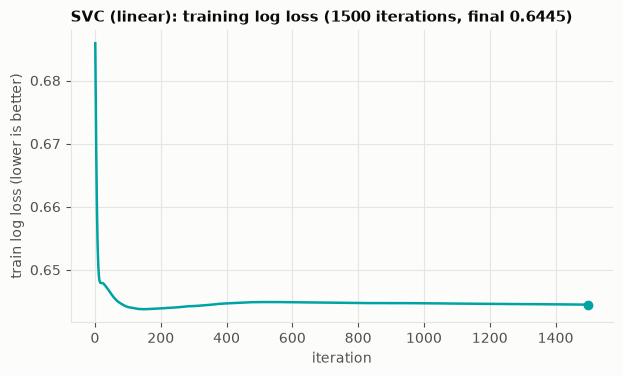

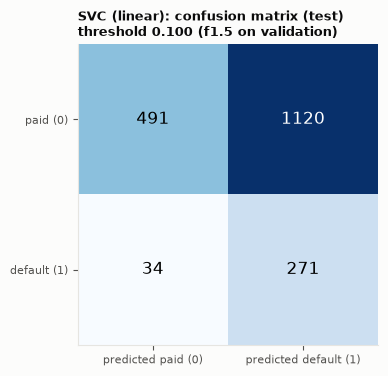

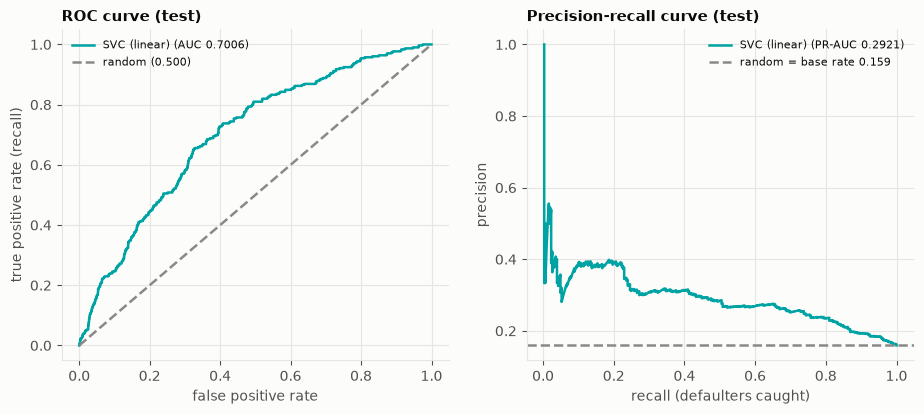

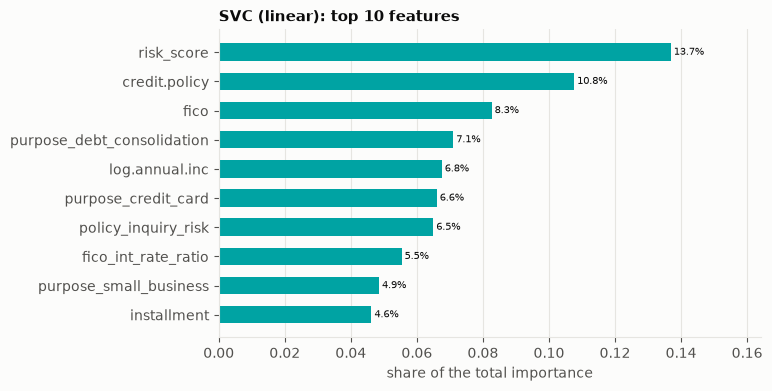


scratch vs library:
  SVC (linear) vs sklearn LinearSVC (same hinge + balanced weights)
    AUC scratch 0.7006 | AUC library 0.6884 | share of same flags = 0.605

saved + reloaded TrainedModels/Classification/06_SVC_Linear.joblib (identical predictions: True)


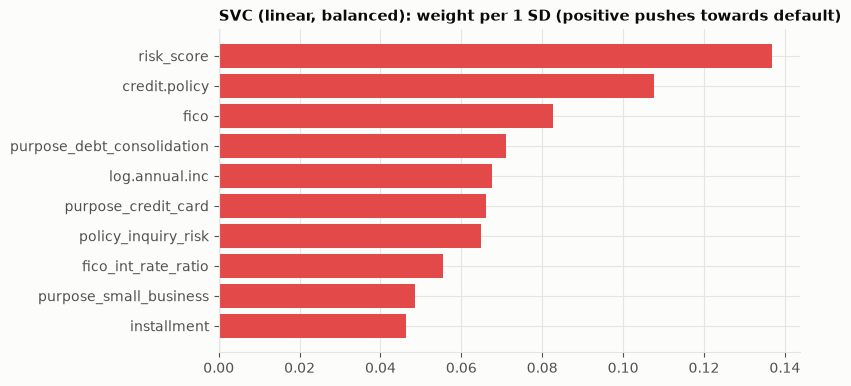

In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "SVC (linear)", model, d, check)

# the weights of the hyperplane (per 1 SD): positive pushes towards default
w = pd.Series(dict(model.feature_importance_table())).sort_values(ascending=False)
w.rename("weight_per_1SD").to_csv(out.table("svc_weights.csv"), index_label="feature")
fig, ax = plots.plt.subplots(figsize=(7.5, 4.2))
top = w.head(10)[::-1]
ax.barh(top.index, top.values, color=[plots.RED if v > 0 else plots.BLUE for v in top.values])
ax.axvline(0, color=plots.NEUTRAL, linewidth=0.8)
ax.set_title("SVC (linear, balanced): weight per 1 SD (positive pushes towards default)")
plots._save(fig, out.image("svc_weights.png"))